# **Prediksi Karakteristik Penguin Menggunakan Model KMeans**

## **1. Bussines Understanding**

### **1.1 Latar Belakang**

Sebuah perusahaan konservasi margasatwa dan peneliti ingin membanugn sistem AI untuk mengelompokkan karakteristik penguin secara otomatis.

### **1.2 Tujuan**

Membangun sistem AI untuk memprediksi karakteristik penguin secara otomatis berdasarkan karakteristik fisik populasi penguin

### **1.3 Masalah**

Dalam proses penelitian, tim peniliti selalu kelapangan untuk mencari hasil penelitan dan tidak efisien baik waktu dan biaya


### **1.4 Solusi**

Solusi adalah dengan membangun sistem AI dengan menggunakan KMeans untuk memprediksi karakteristik penguin secara otomatis

### **1.5 Deskripsi tabel**

`Fitur Input (X): Kolom atribut fisik dan anatomi tubuh penguin, yang meliputi:`
-  culmen_length_mm: Panjang paruh penguin (culmen length) (satuan:
milimeter).
-  culmen_depth_mm: Kedalaman paruh penguin (culmen depth) (satuan:
milimeter).
-  flipper_length_mm: Panjang sirip penguin (flipper length) (satuan: milimeter).
-  body_mass_g: Berat badan penguin (satuan: gram).
-  sex: Jenis kelamin penguin (MALE / FEMALE).


`Target Label (Y): Tidak ada label target (karena menggunakan pembelajaran tanpa
pengawasan / unsupervised learning), di mana algoritma bertugas menemukan
kelompok klaster secara mandiri.`

## **2. Data Preparation**


In [86]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import tkinter as tk
from tkinter import ttk


In [87]:
# df = pd.read_csv('penguins.csv',na_values='.')
df = pd.read_csv('../dataset/penguins.csv', na_values='.')
df.head(10)

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE
5,39.3,20.6,190.0,3650.0,MALE
6,38.9,17.8,181.0,3625.0,FEMALE
7,39.2,19.6,195.0,4675.0,MALE
8,34.1,18.1,193.0,3475.0,NaN
9,42.0,20.2,5000.0,4250.0,MALE


In [88]:
df.info()
df.describe()
df.size

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                334 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB


1720

Terlihat dari dataset ini terdapat 344 baris data dan 5 kolom, dengan tipe data float dan string. Kemudian dataset ini memiliki frame data yaitu 1720. 

In [89]:
df.isnull().sum()

culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64

Terlihat pada dataset ini terdapat 17 missing value.

In [90]:
df.duplicated().sum()


np.int64(1)

Terlihat pada dataset ini terdapat 1 duplicate value.

## **3. Exploratory Data Analysis**

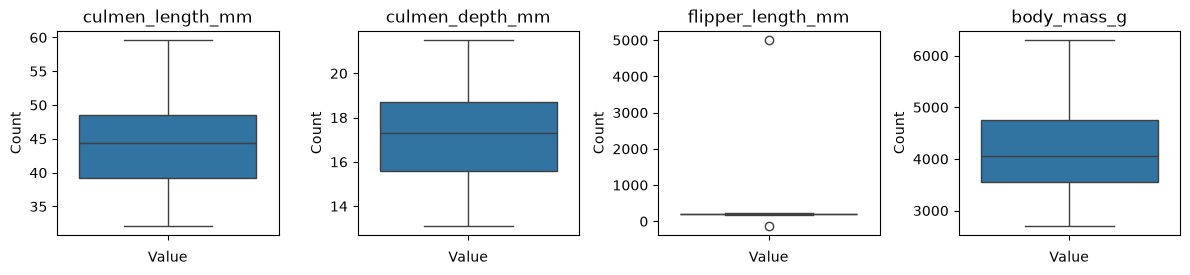

In [91]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(12, 10))

for i, cols in enumerate(cols, start=1):
    plt.subplot(4, 4, i)
    sns.boxplot(df[cols])
    plt.title(cols)
    plt.xlabel('Value')
    plt.ylabel('Count')

plt.tight_layout(h_pad=1.0, w_pad=1.0)
plt.show()

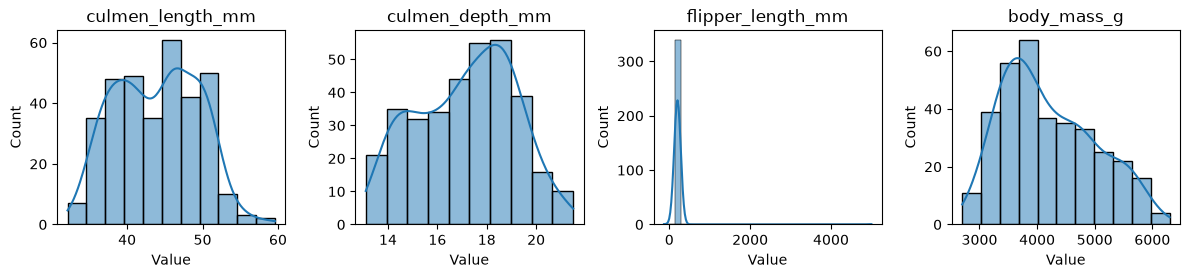

In [92]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(12, 10))

for i, cols in enumerate(cols, start=1):
    plt.subplot(4, 4, i)
    sns.histplot(df[cols], kde=True)
    plt.title(cols)
    plt.xlabel('Value')
    plt.ylabel('Count')

plt.tight_layout(h_pad=1.0, w_pad=1.0)
plt.show()

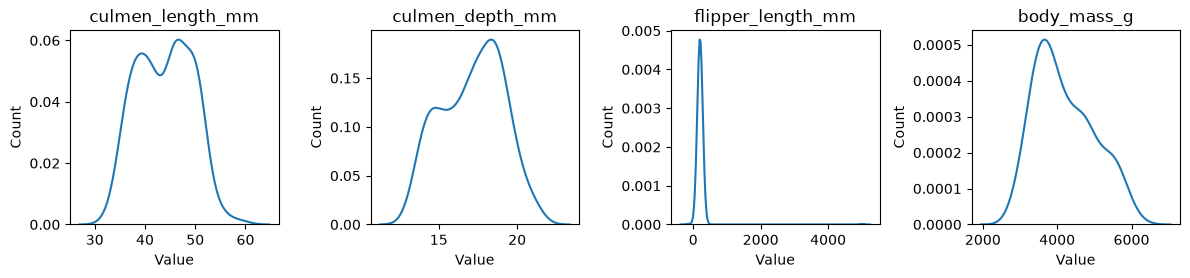

In [93]:
cols = df.select_dtypes(include=['number']).columns

plt.figure(figsize=(12, 10))

for i, cols in enumerate(cols, start=1):
    plt.subplot(4, 4, i)
    sns.kdeplot(df[cols])
    plt.title(cols)
    plt.xlabel('Value')
    plt.ylabel('Count')

plt.tight_layout(h_pad=1.0, w_pad=1.0)
plt.show()

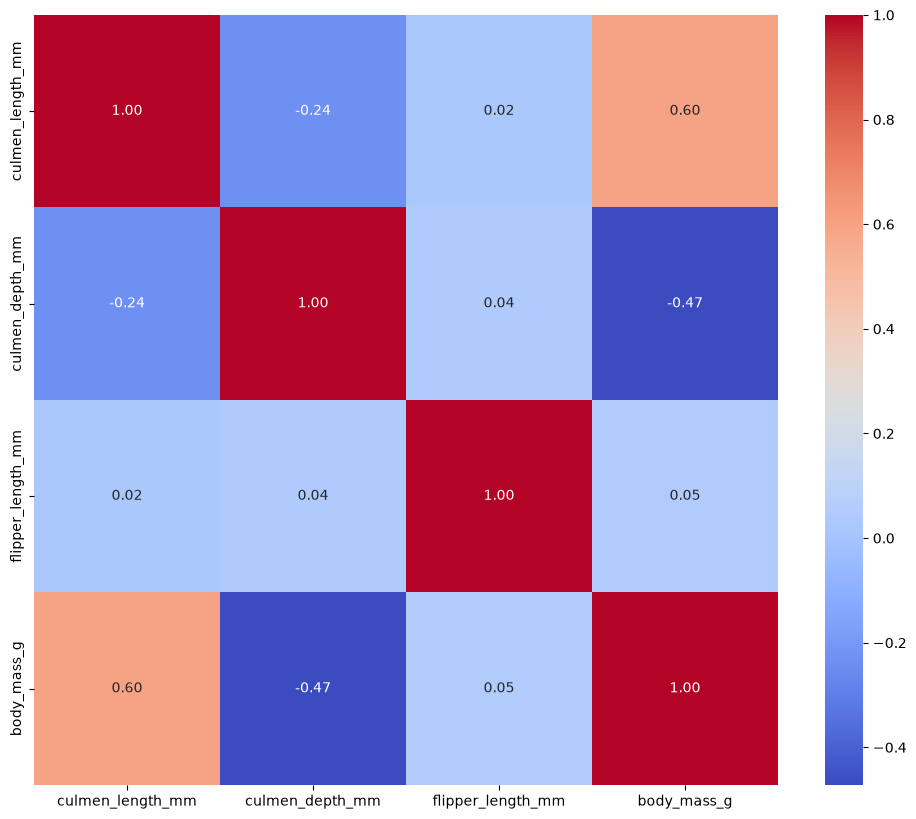

In [94]:
df_corr = df.select_dtypes(include=['number'])

plt.figure(figsize=(12, 10))

sns.heatmap(df_corr.corr(), annot=True, cmap='coolwarm', fmt=".2f")   
plt.show()

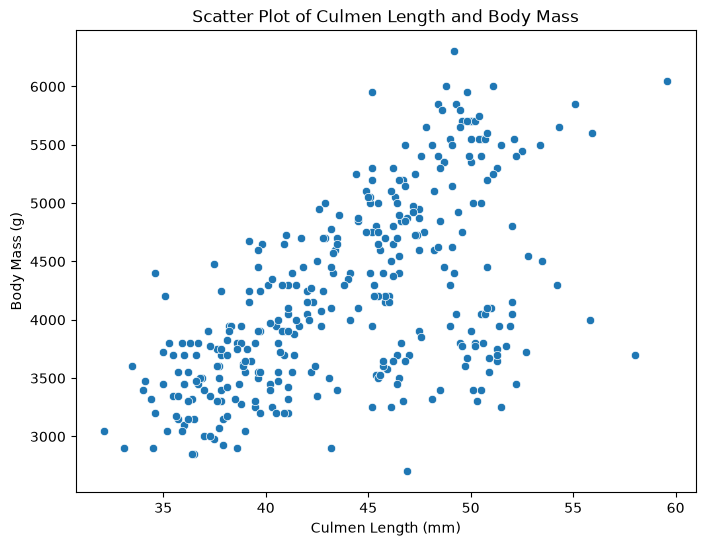

In [95]:
plt.figure(figsize=(8, 6))

sns.scatterplot(x='culmen_length_mm', y='body_mass_g', data=df)
plt.title('Scatter Plot of Culmen Length and Body Mass')
plt.xlabel('Culmen Length (mm)')
plt.ylabel('Body Mass (g)')
plt.show()
plt.close()

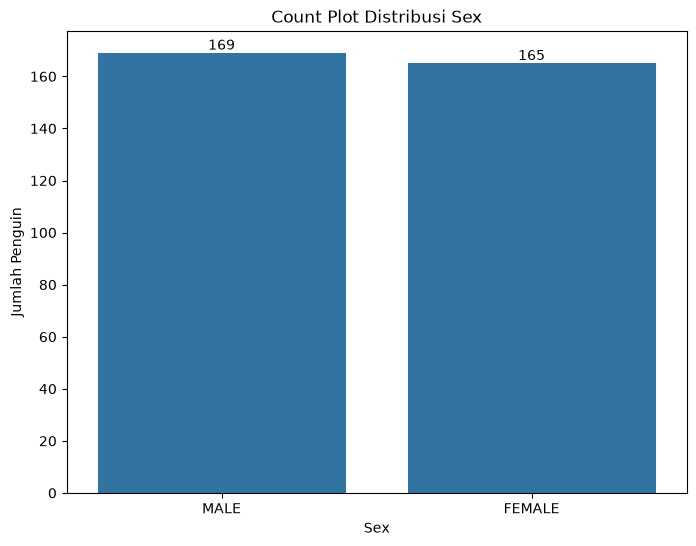

sex               FEMALE  MALE
rentang_mass                  
(2696.4, 3420.0]      52     4
(3420.0, 4140.0]      55    66
(4140.0, 4860.0]      42    39
(4860.0, 5580.0]      16    38
(5580.0, 6300.0]       0    22


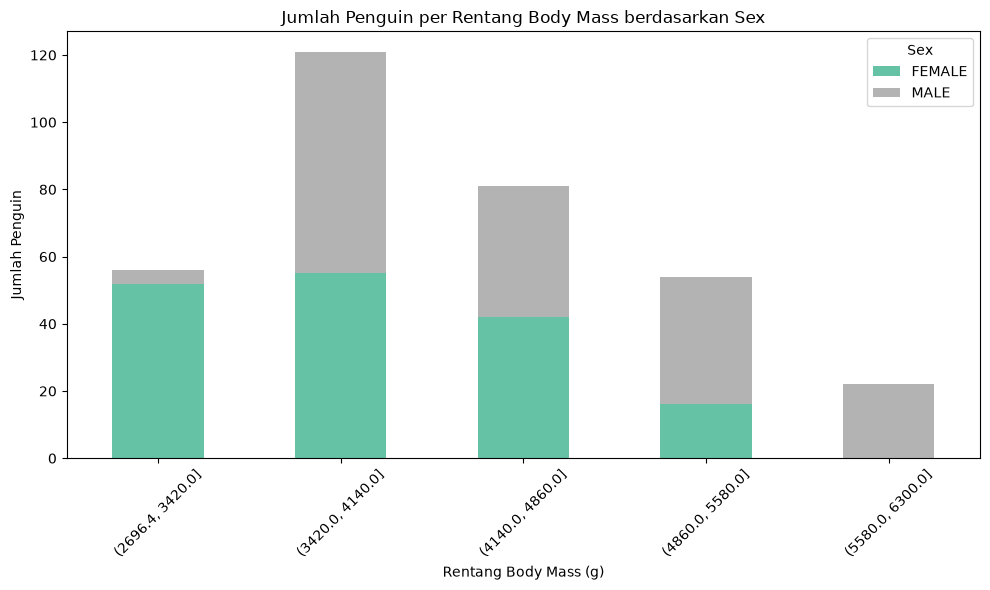

In [96]:
# --- Count Plot: jumlah penguin per kategori sex ---
plt.figure(figsize=(8, 6))
ax = sns.countplot(x='sex', data=df, order=df['sex'].value_counts().index)
ax.bar_label(ax.containers[0])
plt.title('Count Plot Distribusi Sex')
plt.xlabel('Sex')
plt.ylabel('Jumlah Penguin')
plt.show()
plt.close()

# --- Stacked Bar: jumlah penguin per rentang body mass ditumpuk berdasarkan sex ---
df_eda = df.dropna(subset=['sex']).copy()
df_eda['rentang_mass'] = pd.cut(df_eda['body_mass_g'], bins=5)

tabel = pd.crosstab(df_eda['rentang_mass'], df_eda['sex'])
print(tabel)

tabel.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='Set2')
plt.title('Jumlah Penguin per Rentang Body Mass berdasarkan Sex')
plt.xlabel('Rentang Body Mass (g)')
plt.ylabel('Jumlah Penguin')
plt.legend(title='Sex')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
plt.close()

## **4. Data Preprocessing**

In [97]:
# Menghapus data duplikat
df = df.drop_duplicates()

# Reset index setelah penghapusan
df = df.reset_index(drop=True)

In [98]:
df.dropna(inplace=True)

In [99]:
df.isnull().sum()

culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

In [100]:
df.duplicated().sum()

np.int64(0)

In [101]:
df['sex'] = df['sex'].map({'MALE': 0, 'FEMALE': 1})


In [102]:
cols = df.select_dtypes(include=['number']).columns

Q1 =  df[cols].quantile(0.25)
Q3 =  df[cols].quantile(0.75)

IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

outlier = ((df[cols] < batas_bawah)| (df[cols] > batas_atas))
outlier_sebelum = outlier.sum()

df = df.loc[~outlier.any(axis=1)].reset_index(drop=True)

outlier_sesudah = ((df[cols] < batas_bawah)| (df[cols] > batas_atas)).sum()

print(outlier_sebelum)
print('===========================')
print(outlier_sesudah)

culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    2
body_mass_g          0
sex                  0
dtype: int64
culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64


In [103]:
df.isnull().sum()

culmen_length_mm     0
culmen_depth_mm      0
flipper_length_mm    0
body_mass_g          0
sex                  0
dtype: int64

In [104]:

X = df[['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm',
       'body_mass_g', 'sex']]
print(X)

     culmen_length_mm  culmen_depth_mm  flipper_length_mm  body_mass_g  sex
0                39.1             18.7              181.0       3750.0    0
1                39.5             17.4              186.0       3800.0    1
2                40.3             18.0              195.0       3250.0    1
3                36.7             19.3              193.0       3450.0    1
4                39.3             20.6              190.0       3650.0    0
..                ...              ...                ...          ...  ...
327              47.2             13.7              214.0       4925.0    1
328              46.8             14.3              215.0       4850.0    1
329              50.4             15.7              222.0       5750.0    0
330              45.2             14.8              212.0       5200.0    1
331              49.9             16.1              213.0       5400.0    0

[332 rows x 5 columns]


## **5.0 Modeling**

In [105]:
class KMeans:
    def __init__(self,k=3,max_iter=100,random_state= 89):
        self.k = k
        self.max_iter = max_iter
        self.random_state = random_state
        
    def hitung_jarak(self, X):
        return np.sqrt(((X-self.centroid[:, np.newaxis])**2).sum(axis=2))
    
    def fit(self, X):
        X = np.asarray(X, dtype=float)
        np.random.seed(self.random_state) 
        n_sampel = len(X)
        index = np.random.choice(n_sampel, self.k, replace=False)
        self.centroid = X[index]
        
        for _ in range(self.max_iter):
            self.labels = np.argmin(self.hitung_jarak(X), axis=0)
            centroid_baru = np.array([
                X[self.labels == i].mean(axis=0)
                if np.any(self.labels == i)
                else X[np.random.choice(len(X))]
                for i in range(self.k)
            ])
            if np.allclose(self.centroid , centroid_baru):
                break    
            self.centroid = centroid_baru 
         
        self.wcss = sum(np.sum((X[self.labels == i] - self.centroid[i]) **2) for i in range(self.k))   
        return self
    
    def predict(self,X):
        X = np.asarray(X, dtype = float)
        return np.argmin(self.hitung_jarak(X), axis=0)
               

In [106]:
# mean = X.mean(axis=0)
# std = X.std(axis=0)
# std = np.where(std == 0,1.0, std)
# X_s = (X - mean) / std

min_v = X.min(axis=0)
max_v = X.max(axis=0)
rentang = max_v - min_v
rentang = np.where(rentang == 0,1.0, rentang)
X_s = (X - min_v) / rentang

model = KMeans(k=4,random_state=89)
model.fit(X_s)
print('label', model.labels)
print('wcss', model.wcss)

label [3 2 2 2 3 2 3 2 3 2 2 3 2 3 2 3 2 3 3 2 3 2 2 3 2 3 2 3 2 3 3 2 2 3 2 3 2
 3 2 3 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2
 3 2 3 2 3 3 2 3 2 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3
 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 3 2 2 3 2 3 2 3 3
 2 3 2 2 3 2 3 2 3 2 3 2 3 3 2 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 3 2 2 3 2 3
 3 2 3 2 2 3 2 3 3 2 2 3 2 3 2 3 2 3 3 2 3 2 2 3 2 3 3 2 1 0 1 0 0 1 1 0 1
 0 1 0 1 0 1 0 1 0 1 0 0 1 1 0 1 0 0 1 0 0 1 1 0 1 0 1 0 1 0 1 0 1 0 0 1 1
 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 0 1 0 1 0 0 1 1 0 1 0 1 0 1 0 1 0 1
 0 1 0 1 0 1 0 1 0 1 0 0 1 1 0 1 0 1 0 0 1 0 1 0 1 0 1 0 1 0 0 1 1 0 1 0]
wcss 17.51096883093649


label [2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 2 2 2 2 2 2 0 2 0
 2 2 2 2 2 0 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 2 2 0 2 1 0 1 0 0 1 1 0 1
 0 1 0 1 0 1 0 1 0 1 0 0 1 1 0 1 0 0 1 0 0 1 1 0 1 0 1 0 1 0 1 0 1 0 0 1 1
 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 0 1 0 1 0 0 1 1 0 1 0 1 0 1 0 1 0 1
 0 1 0 1 0 1 0 1 0 1 0 0 1 1 0 1 0 1 0 0 1 0 1 0 1 0 1 0 1 0 0 1 1 0 1 0]

sse 683.2125166033474

## **6.0 Evaluasi Model**

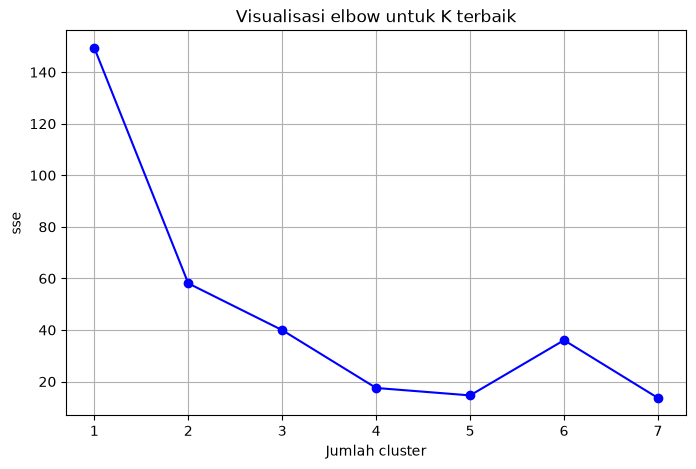

In [107]:
sse_list=[]
ks = range(1,8)
for k in ks:
    model_k = KMeans(k=k,random_state=89)
    model_k.fit(X_s)
    
    sse_list.append(model_k.wcss)

plt.figure(figsize=(8,5))
plt.plot(ks,sse_list, 'bo-')
plt.grid(True)
plt.title("Visualisasi elbow untuk K terbaik")
plt.xlabel('Jumlah cluster')
plt.ylabel("sse")
plt.show()

K = 2 -> Silhouette Score: 0.5607
K = 3 -> Silhouette Score: 0.5581
K = 4 -> Silhouette Score: 0.6153
K = 5 -> Silhouette Score: 0.5674

Jumlah cluster terbaik berdasarkan Silhouette Score: K = 4


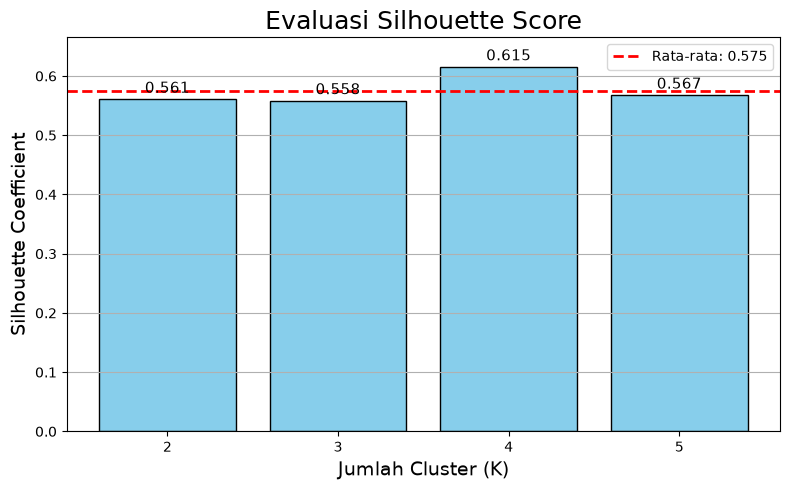

In [108]:
# ============================================================
# Rumus Silhouette Score (sesuai kode di bawah)
# ============================================================
#
# 1. Matriks jarak Euclid antar semua titik
#    rumus : jarak[i][j] = akar( jumlah (X_im - X_jm) kuadrat )
#    kode  : jarak = np.sqrt(((X[:, np.newaxis, :] - X[np.newaxis, :, :]) ** 2).sum(axis=2))
#
# 2. Ambil indeks titik yang satu cluster
#    kode  : sama = np.where(labels == labels[i])[0]
#    kalau anggota cluster hanya 1 titik -> sil[i] = 0
#
# 3. a = kohesi, jarak rata-rata ke cluster sendiri
#    rumus : a = 1 / (n_c - 1) x jumlah jarak ke titik lain di cluster yang sama
#    kode  : a = jarak[i, sama[sama != i]].mean()
#
# 4. b = separasi, jarak rata-rata ke cluster lain yang paling dekat
#    rumus : b = nilai terkecil dari ( 1 / n_k x jumlah jarak ke titik di cluster k )
#    kode  : b = np.min([jarak[i, labels == k].mean() for k in unik if k != labels[i]])
#
# 5. Nilai silhouette titik i
#    rumus : s(i) = (b - a) / nilai terbesar antara a dan b
#    kode  : pembagi = np.max([a, b])
#            sil[i] = (b - a) / pembagi
#
# 6. Silhouette Score keseluruhan
#    rumus : S = 1 / n x jumlah semua s(i), rentang nilai -1 sampai 1
#    kode  : return sil.mean()
#
# 7. Normalisasi min-max sebelum clustering
#    rumus : x_baru = (x - nilai minimum) / (nilai maksimum - nilai minimum)
#    kode  : X_s_clean = (X_clean - min_v) / rentang_v
# ============================================================

# Evaluasi Silhouette Score untuk menentukan jumlah cluster (K) terbaik

# Implementasi Silhouette Score manual
def silhouette_score(X, labels):
    X = np.asarray(X, dtype=float)
    labels = np.asarray(labels)
    n = len(X)
    unik = np.unique(labels)

    # matriks jarak Euclidean antar semua titik
    jarak = np.sqrt(((X[:, np.newaxis, :] - X[np.newaxis, :, :]) ** 2).sum(axis=2))

    sil = np.zeros(n)
    for i in range(n):
        sama = np.where(labels == labels[i])[0]
        if len(sama) == 1:  # klaster berisi 1 titik -> silhouette = 0
            sil[i] = 0.0
            continue
        a = jarak[i, sama[sama != i]].mean()  # jarak rata-rata ke klaster sendiri
        b = np.min([jarak[i, labels == k].mean() for k in unik if k != labels[i]])  # ke klaster terdekat lain
        pembagi = np.max([a, b])
        sil[i] = (b - a) / pembagi if pembagi > 0 else 0.0

    return sil.mean()

# Pastikan data bersih (hapus baris dengan nilai NaN akibat mapping sex)
df_clean = df.dropna().copy()
X_clean = df_clean[['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm',
                    'body_mass_g', 'sex']].values.astype(float)

min_v = X_clean.min(axis=0)
max_v = X_clean.max(axis=0)
rentang_v = max_v - min_v
rentang_v = np.where(rentang_v == 0, 1.0, rentang_v)
X_s_clean = (X_clean - min_v) / rentang_v

ks_eval = range(2, 6)  # K = 2, 3, 4, 5
silhouette_scores = []

for k in ks_eval:
    model_k = KMeans(k=k, random_state=89)
    model_k.fit(X_s_clean)
    score = silhouette_score(X_s_clean, model_k.labels)
    silhouette_scores.append(score)
    print(f'K = {k} -> Silhouette Score: {score:.4f}')

best_k = list(ks_eval)[np.argmax(silhouette_scores)]
print(f'\nJumlah cluster terbaik berdasarkan Silhouette Score: K = {best_k}')

# Visualisasi Silhouette Score
plt.figure(figsize=(8, 5))
bars = plt.bar(list(ks_eval), silhouette_scores, color='#87CEEB', edgecolor='black')

# Garis putus-putus merah (rata-rata silhouette score)
avg_score = np.mean(silhouette_scores)
plt.axhline(y=avg_score, color='red', linestyle='--', linewidth=2,
            label=f'Rata-rata: {avg_score:.3f}')

# Anotasi nilai di atas setiap bar
for bar, score in zip(bars, silhouette_scores):
    plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.005,
             f'{score:.3f}', ha='center', va='bottom', fontsize=11)

plt.title('Evaluasi Silhouette Score', fontsize=18)
plt.xlabel('Jumlah Cluster (K)', fontsize=14)
plt.ylabel('Silhouette Coefficient', fontsize=14)
plt.xticks(list(ks_eval))
plt.ylim(0, np.max(silhouette_scores) + 0.05)
plt.grid(True, axis='y')
plt.legend()
plt.tight_layout(w_pad=4, h_pad=2)
plt.show()


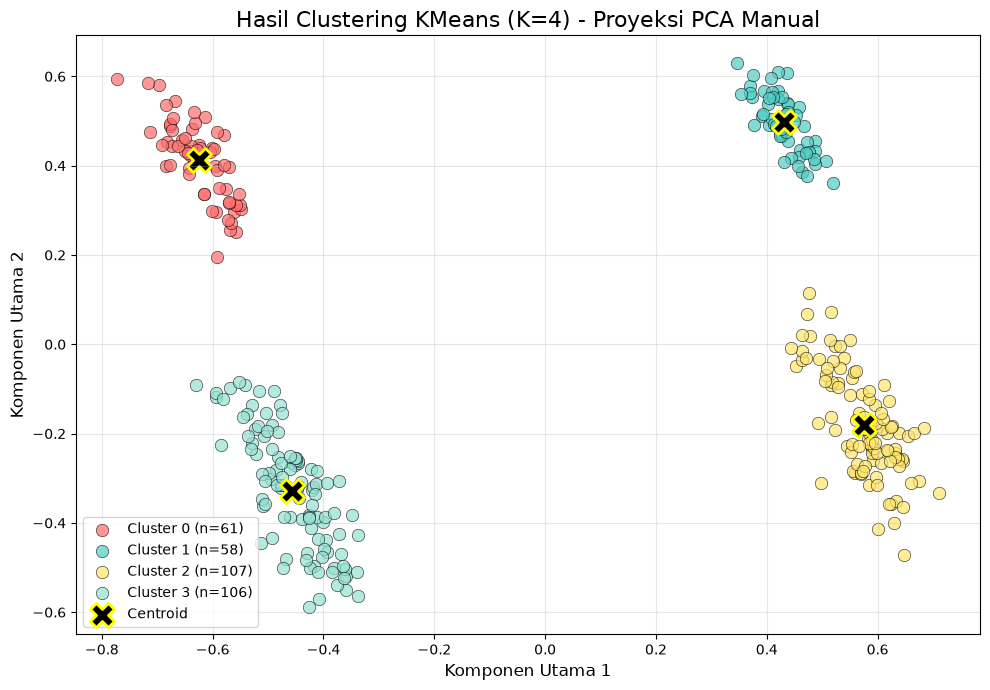

In [109]:
# ============================================================
# Rumus Visualisasi Clustering PCA Manual (sesuai kode di bawah)
# ============================================================
#
# 1. Centering data
#    rumus : X_centered = X_s_clean - X_mean
#            dengan X_mean = rata-rata tiap fitur
#    kode  : X_mean = X_s_clean.mean(axis=0)
#            X_centered = X_s_clean - X_mean
#
# 2. Matriks kovarians
#    rumus : cov = 1 / (n - 1) x (X_centered transpose dikali X_centered)
#    kode  : cov = np.cov(X_centered, rowvar=False)
#
# 3. Dekomposisi eigen
#    rumus : cov dikali v = lambda dikali v
#    kode  : eigvals, eigvecs = np.linalg.eigh(cov)
#
# 4. Urutkan eigenvalue dari besar ke kecil
#    rumus : lambda_1 lebih besar atau sama dengan lambda_2 sampai lambda_p
#    kode  : urut = np.argsort(eigvals)[::-1]
#
# 5. Ambil 2 eigenvector utama sebagai W
#    kode  : W = eigvecs[:, urut][:, :2]
#
# 6. Proyeksi data ke 2 dimensi
#    rumus : X_pca = X_centered dikali W
#    kode  : X_pca = X_centered @ W
#
# 7. Proyeksi centroid
#    rumus : centroids_pca = (centroids - X_mean) dikali W
#    kode  : centroids_pca = (centroids - X_mean) @ W
#
# 8. Variansi yang dijelaskan (opsional)
#    rumus : (lambda_1 + lambda_2) dibagi jumlah semua lambda, dikali 100 persen
# ============================================================

# Visualisasi hasil clustering - scatter 2D menggunakan PCA manual

# Fit model akhir dengan K terbaik dari evaluasi silhouette
model_akhir = KMeans(k=best_k, random_state=89)
model_akhir.fit(X_s_clean)
labels_akhir = model_akhir.labels
centroids = model_akhir.centroid

# --- PCA Manual (eigendecomposition) untuk reduksi ke 2D ---
X_mean = X_s_clean.mean(axis=0)
X_centered = X_s_clean - X_mean
cov = np.cov(X_centered, rowvar=False)
eigvals, eigvecs = np.linalg.eigh(cov)
urut = np.argsort(eigvals)[::-1]          # urut eigenvalue menurun
W = eigvecs[:, urut][:, :2]               # 2 vektor eigen utama
X_pca = X_centered @ W
centroids_pca = (centroids - X_mean) @ W

warna = ['#FF6B6B', '#4ECDC4', '#FFE66D', '#95E1D3', '#C7CEEA']

plt.figure(figsize=(10, 7))
for c in range(best_k):
    mask = labels_akhir == c
    plt.scatter(X_pca[mask, 0], X_pca[mask, 1],
                c=warna[c % len(warna)], s=80, alpha=0.7,
                edgecolor='black', linewidth=0.5,
                label=f'Cluster {c} (n={int(np.sum(mask))})')

# Titik centroid
plt.scatter(centroids_pca[:, 0], centroids_pca[:, 1],
            c='black', marker='X', s=300, edgecolor='yellow',
            linewidth=2, label='Centroid')

plt.title(f'Hasil Clustering KMeans (K={best_k}) - Proyeksi PCA Manual', fontsize=16)
plt.xlabel('Komponen Utama 1', fontsize=12)
plt.ylabel('Komponen Utama 2', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## **7. GUI**

In [ ]:
# ============================================================
# 2. KONFIGURASI FITUR
# ============================================================

KONFIGURASI = {
    "culmen_length_mm": {
        "label": "Panjang Paruh (mm)",
        "type": "number",
        "default": 39.1
    },

    "culmen_depth_mm": {
        "label": "Kedalaman Paruh (mm)",
        "type": "number",
        "default": 18.7
    },

    "flipper_length_mm": {
        "label": "Panjang Sirip (mm)",
        "type": "number",
        "default": 181.0
    },

    "body_mass_g": {
        "label": "Massa Badan (g)",
        "type": "number",
        "default": 3750.0
    },

    "sex": {
        "label": "Jenis Kelamin",
        "type": "category",
        "mapping": {
            "MALE": 0,
            "FEMALE": 1
        },
        "default": "MALE"
    }
}   

# Mengambil nama fitur secara otomatis
FITUR = list(KONFIGURASI.keys())

# Mapping kategori
MAPPING_KATEGORI = {
    kolom: config["mapping"]
    for kolom, config in KONFIGURASI.items()
    if config["type"] == "category"
}

# Mapping terbalik
INV_MAPPING = {
    kolom: {
        nilai: nama
        for nama, nilai in mapping.items()
    }
    for kolom, mapping in MAPPING_KATEGORI.items()
}


# ============================================================
# 3. VALIDASI DATA TRAINING
# ============================================================

labels = np.asarray(labels_akhir)

if len(df_clean) != len(labels):
    raise ValueError(
        "Jumlah data df_clean tidak sama dengan labels_akhir."
    )

if not all(kolom in df_clean.columns for kolom in FITUR):
    raise ValueError(
        "Ada fitur yang tidak ditemukan dalam df_clean."
    )


# ============================================================
# 4. PROFIL CLUSTER
# ============================================================

def buat_profil_cluster():

    hasil = {}

    for cluster in range(best_k):

        data = df_clean.loc[
            labels == cluster,
            FITUR
        ]

        if data.empty:
            raise ValueError(
                f"Cluster {cluster} tidak memiliki data."
            )

        hasil[cluster] = {}

        for kolom, config in KONFIGURASI.items():

            if config["type"] == "number":

                hasil[cluster][kolom] = float(
                    data[kolom].mean()
                )

            elif config["type"] == "category":

                hasil[cluster][kolom] = (
                    data[kolom]
                    .value_counts(normalize=True)
                    .to_dict()
                )

    return hasil


# Menghitung profil cluster satu kali
PROFILES = buat_profil_cluster()


# ============================================================
# 5. PARAMETER NORMALISASI
# ============================================================

# min_v dan rentang_v diasumsikan berupa NumPy array.
# Urutannya harus sama dengan FITUR.

MIN_V = np.asarray(
    min_v,
    dtype=float
).reshape(-1)

RENTANG_V = np.asarray(
    rentang_v,
    dtype=float
).reshape(-1)


# Validasi jumlah parameter
if len(MIN_V) != len(FITUR):
    raise ValueError(
        f"Jumlah MIN_V ({len(MIN_V)}) tidak sesuai "
        f"dengan jumlah fitur ({len(FITUR)})."
    )

if len(RENTANG_V) != len(FITUR):
    raise ValueError(
        f"Jumlah RENTANG_V ({len(RENTANG_V)}) tidak sesuai "
        f"dengan jumlah fitur ({len(FITUR)})."
    )


# Validasi nilai parameter
if not np.all(np.isfinite(MIN_V)):
    raise ValueError("MIN_V mengandung nilai tidak valid.")

if not np.all(np.isfinite(RENTANG_V)):
    raise ValueError("RENTANG_V mengandung nilai tidak valid.")

if np.any(RENTANG_V < 0):
    raise ValueError("RENTANG_V tidak boleh negatif.")


# Mencegah pembagian dengan nol
RENTANG_AMAN = np.where(
    RENTANG_V == 0,
    1,
    RENTANG_V
)


# ============================================================
# 6. LOGIKA MACHINE LEARNING
# ============================================================

def normalisasi_data(data):

    x = np.array(
        [[data[kolom] for kolom in FITUR]],
        dtype=float
    )

    return (x - MIN_V) / RENTANG_AMAN


def prediksi_cluster(data):

    x_skala = normalisasi_data(data)

    cluster = int(
        model_akhir.predict(x_skala)[0]
    )

    if cluster not in PROFILES:
        raise ValueError(
            f"Cluster {cluster} tidak ditemukan."
        )

    return cluster


# ============================================================
# 7. FORMAT HASIL CLUSTER
# ============================================================

def format_profil(data, cluster):

    profil = PROFILES[cluster]

    hasil = []

    for kolom, config in KONFIGURASI.items():

        label = config["label"]

        if config["type"] == "number":

            input_nilai = f"{data[kolom]:.2f}"

            rata_rata = f"{profil[kolom]:.2f}"

        elif config["type"] == "category":

            kode = data[kolom]

            input_nilai = INV_MAPPING[kolom][kode]

            rata_rata = " / ".join(
                f"{nama}: "
                f"{profil[kolom].get(kode_kategori, 0) * 100:.0f}%"
                for nama, kode_kategori
                in config["mapping"].items()
            )

        hasil.append(
            f"{label:<25} "
            f"{input_nilai:>14} "
            f"{rata_rata:>25}"
        )

    header = (
        f"{'Fitur':<25} "
        f"{'Input Anda':>14} "
        f"{'Rata-rata Cluster':>25}"
    )

    return "\n".join([
        header,
        "-" * 66,
        *hasil
    ])


# ============================================================
# 8. APLIKASI GUI
# ============================================================

class Aplikasi(tk.Tk):

    def __init__(self):

        super().__init__()

        self.title("KMeans Clustering - Penguin")
        self.geometry("680x650")
        self.resizable(False, False)

        self.entries = {}
        self.combos = {}

        self._build_form()


    # ========================================================
    # MEMBUAT TAMPILAN
    # ========================================================

    def _build_form(self):

        # Header
        header = tk.Frame(
            self,
            bg="#1f4e79",
            height=75
        )

        header.pack(fill="x")

        tk.Label(
            header,
            text="Prediksi Karakteristik Penguin",
            bg="#1f4e79",
            fg="white",
            font=("Segoe UI", 15, "bold")
        ).pack(pady=(12, 0))

        tk.Label(
            header,
            text="KMeans Clustering",
            bg="#1f4e79",
            fg="white",
            font=("Segoe UI", 10)
        ).pack(pady=(0, 12))

        # Panel hasil
        self._build_result()

        # Area form
        container = ttk.Frame(self)

        container.pack(
            fill="both",
            expand=True,
            padx=20,
            pady=15
        )

        canvas = tk.Canvas(
            container,
            highlightthickness=0
        )

        scrollbar = ttk.Scrollbar(
            container,
            orient="vertical",
            command=canvas.yview
        )

        self.form = ttk.Frame(
            canvas,
            padding=10
        )

        self.form_window = canvas.create_window(
            (0, 0),
            window=self.form,
            anchor="nw"
        )

        canvas.configure(
            yscrollcommand=scrollbar.set
        )

        self.form.bind(
            "<Configure>",
            lambda event: canvas.configure(
                scrollregion=canvas.bbox("all")
            )
        )

        canvas.bind(
            "<Configure>",
            lambda event: canvas.itemconfigure(
                self.form_window,
                width=event.width
            )
        )

        canvas.pack(
            side="left",
            fill="both",
            expand=True
        )

        scrollbar.pack(
            side="right",
            fill="y"
        )

        self.form.columnconfigure(
            1,
            weight=1
        )

        # Membuat input
        self._build_inputs()

        # Membuat tombol
        self._build_buttons()


    # ========================================================
    # PANEL HASIL
    # ========================================================

    def _build_result(self):

        self.cluster_var = tk.StringVar(
            value="Hasil prediksi"
        )

        self.result_frame = tk.Frame(
            self,
            bg="#eaf2f8",
            padx=14,
            pady=12
        )

        self.result_frame.pack(
            side="bottom",
            fill="x",
            padx=20,
            pady=(0, 15)
        )

        self.cluster_label = tk.Label(
            self.result_frame,
            textvariable=self.cluster_var,
            font=("Segoe UI", 20, "bold"),
            bg="#eaf2f8",
            fg="#1f4e79",
            anchor="w"
        )

        self.cluster_label.pack(
            fill="x",
            pady=(0, 8)
        )

        # Area hasil dengan scrollbar
        result_container = ttk.Frame(
            self.result_frame
        )

        result_container.pack(
            fill="both",
            expand=True
        )

        self.result_text = tk.Text(
            result_container,
            height=9,
            wrap="none",
            font=("Consolas", 9),
            bg="#eaf2f8",
            fg="#333333",
            relief="flat",
            state="disabled"
        )

        scroll_y = ttk.Scrollbar(
            result_container,
            orient="vertical",
            command=self.result_text.yview
        )

        scroll_x = ttk.Scrollbar(
            result_container,
            orient="horizontal",
            command=self.result_text.xview
        )

        self.result_text.configure(
            yscrollcommand=scroll_y.set,
            xscrollcommand=scroll_x.set
        )

        self.result_text.grid(
            row=0,
            column=0,
            sticky="nsew"
        )

        scroll_y.grid(
            row=0,
            column=1,
            sticky="ns"
        )

        scroll_x.grid(
            row=1,
            column=0,
            sticky="ew"
        )

        result_container.columnconfigure(
            0,
            weight=1
        )

        result_container.rowconfigure(
            0,
            weight=1
        )


    # ========================================================
    # MEMBUAT INPUT DINAMIS
    # ========================================================

    def _build_inputs(self):

        for r, (kolom, config) in enumerate(
            KONFIGURASI.items()
        ):

            ttk.Label(
                self.form,
                text=config["label"],
                font=("Segoe UI", 10)
            ).grid(
                row=r,
                column=0,
                sticky="w",
                padx=(0, 12),
                pady=6
            )

            if config["type"] == "number":

                widget = ttk.Entry(
                    self.form,
                    font=("Segoe UI", 10)
                )

                widget.insert(
                    0,
                    str(config["default"])
                )

                self.entries[kolom] = widget

            elif config["type"] == "category":

                widget = ttk.Combobox(
                    self.form,
                    values=list(
                        config["mapping"].keys()
                    ),
                    state="readonly",
                    font=("Segoe UI", 10)
                )

                widget.set(
                    config["default"]
                )

                self.combos[kolom] = widget

            else:

                raise ValueError(
                    f"Tipe fitur '{config['type']}' "
                    "belum didukung."
                )

            widget.grid(
                row=r,
                column=1,
                sticky="ew",
                pady=6
            )


    # ========================================================
    # MEMBUAT TOMBOL
    # ========================================================

    def _build_buttons(self):

        tombol = ttk.Frame(self.form)

        tombol.grid(
            row=len(KONFIGURASI),
            column=0,
            columnspan=2,
            sticky="ew",
            pady=20
        )

        for kolom in range(3):
            tombol.columnconfigure(
                kolom,
                weight=1
            )

        daftar_tombol = [
            ("Isi Otomatis", self.on_autofill),
            ("Prediksi", self.on_predict),
            ("Reset", self.on_reset)
        ]

        for kolom, (label, aksi) in enumerate(
            daftar_tombol
        ):

            ttk.Button(
                tombol,
                text=label,
                command=aksi
            ).grid(
                row=0,
                column=kolom,
                sticky="ew",
                padx=5,
                ipady=6
            )


    # ========================================================
    # MENAMPILKAN PESAN
    # ========================================================

    def _pesan(
        self,
        teks,
        bg="#f2f2f2",
        fg="#333333"
    ):

        self.result_text.configure(
            state="normal"
        )

        self.result_text.delete(
            "1.0",
            tk.END
        )

        self.result_text.insert(
            "1.0",
            teks
        )

        self.result_text.configure(
            state="disabled",
            bg=bg,
            fg=fg
        )

        self.cluster_label.configure(
            bg=bg,
            fg=fg
        )

        self.result_frame.configure(
            bg=bg
        )


    # ========================================================
    # MENGAMBIL DAN MEMVALIDASI INPUT
    # ========================================================

    def _kumpulkan_input(self):

        data = {}

        # Fitur numerik
        for kolom, entry in self.entries.items():

            teks = (
                entry.get()
                .strip()
                .replace(",", ".")
            )

            if not teks:

                raise ValueError(
                    f"{KONFIGURASI[kolom]['label']} "
                    "tidak boleh kosong."
                )

            try:

                nilai = float(teks)

            except ValueError:

                raise ValueError(
                    f"{KONFIGURASI[kolom]['label']} "
                    "harus berupa angka."
                )

            if not np.isfinite(nilai):

                raise ValueError(
                    f"{KONFIGURASI[kolom]['label']} "
                    "tidak valid."
                )

            data[kolom] = nilai

        # Fitur kategorikal
        for kolom, combo in self.combos.items():

            pilihan = combo.get()

            mapping = KONFIGURASI[kolom]["mapping"]

            if pilihan not in mapping:

                raise ValueError(
                    f"Pilih {KONFIGURASI[kolom]['label']}."
                )

            data[kolom] = mapping[pilihan]

        return data


    # ========================================================
    # PREDIKSI
    # ========================================================

    def on_predict(self):

        try:

            # 1. Mengambil input
            data = self._kumpulkan_input()

            # 2. Prediksi cluster
            cluster = prediksi_cluster(data)

            # 3. Membuat hasil
            teks = format_profil(
                data,
                cluster
            )

            # 4. Menampilkan hasil
            self.cluster_var.set(
                f"TERMASUK CLUSTER {cluster}"
            )

            self._pesan(
                teks,
                "#d9ead3",
                "#1e6b34"
            )

        except ValueError as err:

            self.cluster_var.set(
                "Periksa input"
            )

            self._pesan(
                f"Input tidak valid: {err}",
                "#f8d7da",
                "#a12622"
            )


    # ========================================================
    # ISI OTOMATIS
    # ========================================================

    def on_autofill(self):

        baris = df_clean.sample(
            n=1
        ).iloc[0]

        # Mengisi fitur numerik
        for kolom, entry in self.entries.items():

            entry.delete(
                0,
                tk.END
            )

            entry.insert(
                0,
                str(baris[kolom])
            )

        # Mengisi fitur kategori
        for kolom, combo in self.combos.items():

            kode = int(baris[kolom])

            if kode not in INV_MAPPING[kolom]:

                raise ValueError(
                    f"Kode kategori {kode} "
                    f"tidak ditemukan pada {kolom}."
                )

            nama = INV_MAPPING[kolom][kode]

            combo.set(nama)

        self.cluster_var.set(
            "Data contoh siap"
        )

        self._pesan(
            "Data contoh berhasil diisi. "
            "Tekan Prediksi untuk melihat hasil."
        )


    # ========================================================
    # RESET FORM
    # ========================================================

    def on_reset(self):

        # Reset fitur numerik
        for kolom, entry in self.entries.items():

            entry.delete(
                0,
                tk.END
            )

            entry.insert(
                0,
                str(KONFIGURASI[kolom]["default"])
            )

        # Reset fitur kategori
        for kolom, combo in self.combos.items():

            combo.set(
                KONFIGURASI[kolom]["default"]
            )

        self.cluster_var.set(
            "Hasil prediksi"
        )

        self._pesan(
            "Form berhasil direset. "
            "Silakan masukkan data."
        )


# ============================================================
# 9. MENJALANKAN APLIKASI
# ============================================================

app = Aplikasi()
app.mainloop()
